# 🧪 Практическая работа №1
## Подготовка набора данных для задачи машинного обучения


---

**Предметная задача:** *Прогнозирование оттока клиентов (Customer Churn)* — телеком-компания хочет заранее понимать, какие клиенты собираются уйти к конкурентам, чтобы вовремя предложить им скидку или улучшить обслуживание.

Это классическая задача **классификации**: по характеристикам клиента (тариф, стаж, траты, обращения в поддержку и т. д.) нужно предсказать бинарный признак `churn` — уйдёт клиент (1) или останется (0).

В этой работе мы **не строим модель**. Наша цель — научиться правильно **готовить данные**, что на практике занимает 70–80% времени любого data-специалиста.

---

### 🎯 Что вы будете делать (4 этапа)

| Этап | Название | Что осваиваете |
|------|----------|----------------|
| 1 | Загрузка данных | `pandas`, чтение и первичный осмотр |
| 2 | Разведочный анализ (EDA) + визуализация | `describe`, графики, поиск закономерностей |
| 3 | Предобработка данных | пропуски, выбросы, кодирование, масштабирование |
| 4 | Конструирование и отбор признаков | создание новых признаков, отбор значимых |

---

### ⚠️ ВАЖНО: у каждого студента СВОЙ набор данных

Данные генерируются на основе **вашего персонального ключа** (ФИО + номер по списку группы). У каждого получатся **свои числа, свои графики и свои ответы**.

👉 Заполните ячейку ниже своими данными, прежде чем что-либо запускать.


## 🔑 Шаг 0. Персонализация (обязательно!)

Впишите свои **фамилию, имя** и **номер по списку группы** в переменные ниже.
Из них будет вычислен уникальный `SEED` — «зерно» генератора случайных чисел, определяющее ваш индивидуальный вариант данных.


In [ ]:
# ==========================================================
# ⬇️  ЗАПОЛНИТЕ ЭТИ ТРИ ПОЛЯ СВОИМИ ДАННЫМИ
# ==========================================================
last_name   = "Каширина"   # <-- впишите свою фамилию
first_name  = "Ирина"     # <-- впишите своё имя
list_number = 10          # <-- ваш номер по списку (целое число)
# ==========================================================

import hashlib

def make_seed(last: str, first: str, number: int) -> int:
    """Превращает ФИО и номер в стабильный уникальный seed (0..99999)."""
    key = f"{last.strip().lower()}|{first.strip().lower()}|{int(number)}"
    return int(hashlib.sha256(key.encode("utf-8")).hexdigest(), 16) % 100_000

SEED = make_seed(last_name, first_name, list_number)

print("👤 Студент:", last_name, first_name, f"(№{list_number})")
print("🔑 Ваш персональный SEED:", SEED)
print("\n➡️  Запишите этот SEED в отчёт — он подтверждает ваш вариант.")


👤 Студент: Каширина Ирина (№10)
🔑 Ваш персональный SEED: 53406

➡️  Запишите этот SEED в отчёт — он подтверждает ваш вариант.


> 💡 **Как это работает.** Функция `hashlib.sha256` превращает вашу строку в длинное число, которое мы «обрезаем» до диапазона 0–99999. Одинаковые ФИО+номер всегда дадут один и тот же SEED, а разные — практически всегда разный. Именно SEED управляет всей генерацией данных ниже, поэтому ваш вариант уникален.

## ⚙️ Подготовка окружения

Импортируем библиотеки. В Google Colab все они уже установлены — ничего дополнительно ставить не нужно.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)


## 🏭 Генерация вашего набора данных

Ячейка ниже создаёт **ваш персональный датасет** клиентов телеком-компании на основе `SEED`.


Внутри намеренно заложены «грязные» данные (пропуски, выбросы, дубликаты, разный регистр текста), чтобы этапы предобработки имели смысл.

**Описание признаков:**

| Признак | Смысл |
|---------|-------|
| `client_id` | идентификатор клиента |
| `tenure_months` | сколько месяцев клиент с компанией |
| `monthly_charges` | ежемесячный платёж, руб. |
| `total_charges` | суммарно уплачено за всё время, руб. |
| `contract_type` | тип договора (месячный / годовой / двухлетний) |
| `internet_service` | тип интернета (DSL / оптика / нет) |
| `payment_method` | способ оплаты |
| `support_calls` | число обращений в техподдержку за год |
| `age` | возраст клиента |
| `region` | регион проживания |
| **`churn`** | **ЦЕЛЕВАЯ переменная**: 1 — клиент ушёл, 0 — остался |


In [ ]:
#@title 🏭 Создание персонального датасета (нажмите ▶️, код разбирать не нужно) { display-mode: "form" }

def load_churn_dataset(seed: int, n: int = 1500) -> "pd.DataFrame":
    """Возвращает индивидуальный «грязный» датасет оттока клиентов по seed."""
    rng = np.random.default_rng(seed)

    tenure   = rng.integers(0, 72, size=n)
    monthly  = np.clip(np.round(rng.normal(1500, 500, size=n), 2), 300, None)
    contract = rng.choice(["Месячный", "Годовой", "Двухлетний"], size=n, p=[.55, .25, .20])
    internet = rng.choice(["DSL", "Оптика", "Нет"], size=n, p=[.35, .45, .20])
    payment  = rng.choice(["Карта", "Кошелёк", "Перевод", "Наличные"], size=n)
    support  = rng.poisson(1.5, size=n)
    age      = rng.integers(18, 80, size=n)
    region   = rng.choice(["Москва", "СПб", "Центр", "Юг", "Урал"], size=n)
    total    = np.round(monthly * np.maximum(tenure, 1) * rng.uniform(.9, 1.1, size=n), 2)

    logit = (-1.0 + 0.9*(contract == "Месячный") - 0.6*(contract == "Двухлетний")
             + 0.05*support - 0.02*tenure + 0.0004*(monthly - 1500) + 0.3*(internet == "Оптика"))
    churn = (rng.uniform(size=n) < 1/(1 + np.exp(-logit))).astype(int)

    df = pd.DataFrame({
        "client_id": np.arange(1, n + 1), "tenure_months": tenure,
        "monthly_charges": monthly, "total_charges": total,
        "contract_type": contract, "internet_service": internet,
        "payment_method": payment, "support_calls": support,
        "age": age, "region": region, "churn": churn})

    # намеренно «портим» данные, чтобы было что чистить
    df.loc[rng.choice(n, int(.05*n), replace=False), "total_charges"]   = np.nan
    df.loc[rng.choice(n, int(.03*n), replace=False), "monthly_charges"] = np.nan
    df.loc[rng.choice(n, 8, replace=False), "monthly_charges"] *= 12          # выбросы
    ridx = rng.choice(n, int(.1*n), replace=False)
    df.loc[ridx, "region"] = df.loc[ridx, "region"].str.upper()               # разный регистр
    df = pd.concat([df, df.sample(int(.02*n), random_state=seed)], ignore_index=True)  # дубликаты
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)

print("✅ Функция load_churn_dataset готова к использованию.")


✅ Функция load_churn_dataset готова к использованию.


Теперь загрузим **ваш** набор данных одной строкой — просто вызвав готовую функцию:

In [ ]:
# Загружаем ваш персональный датасет вызовом готовой функции
df_raw = load_churn_dataset(SEED)

print("Ваш датасет создан. Размер:", df_raw.shape)


Ваш датасет создан. Размер: (1530, 11)


> ℹ️ Обратите внимание: в вашем датасете уже «спрятаны» пропуски, выбросы, дубликаты и неаккуратный текст. Найти и исправить их — часть заданий.

---
# 📥 Этап 1. Загрузка и первичный осмотр данных

**Цель:** убедиться, что данные загружены, понять их размер, типы столбцов и общий вид.

### 📖 Пример

Ниже — образцы стандартных команд первичного осмотра. Изучите их, они пригодятся в задании.


In [ ]:
# --- ПРИМЕР: базовый осмотр датасета ---

print("\nПервые 5 строк:")
display(df_raw.head())

print("\nОбщая информация:")
df_raw.info()



Первые 5 строк:


,client_id,tenure_months,monthly_charges,total_charges,contract_type,internet_service,payment_method,support_calls,age,region,churn
0,980,57,1696.05,92962.82,Месячный,Оптика,Кошелёк,0,24,СПб,1
1,966,43,1758.44,72569.77,Месячный,DSL,Перевод,0,34,МОСКВА,0
2,894,33,1026.57,30562.35,Месячный,Оптика,Кошелёк,3,33,Москва,1
3,1241,15,1023.31,14519.89,Месячный,Оптика,Карта,0,68,Москва,0
4,700,58,2123.13,125396.71,Месячный,Нет,Наличные,2,64,Урал,0



Общая информация:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1530 entries, 0 to 1529
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   client_id         1530 non-null   int64  
 1   tenure_months     1530 non-null   int64  
 2   monthly_charges   1484 non-null   float64
 3   total_charges     1453 non-null   float64
 4   contract_type     1530 non-null   object 
 5   internet_service  1530 non-null   object 
 6   payment_method    1530 non-null   object 
 7   support_calls     1530 non-null   int64  
 8   age               1530 non-null   int64  
 9   region            1530 non-null   object 
 10  churn             1530 non-null   int64  
dtypes: float64(2), int64(5), object(4)
memory usage: 131.6+ KB


### ✍️ Задание 1

В ячейке ниже, используя методы `pandas`, выполните:

1. Выведите **последние 7 строк** датасета (метод `.tail()`).
2. Посчитайте, **сколько всего дубликатов строк** в ваших данных (`.duplicated().sum()`).
3. Выведите **число уникальных значений** в каждом текстовом столбце (`contract_type`, `internet_service`, `payment_method`, `region`).



In [ ]:
# ▼▼▼ ВАШ КОД (Задание 1) ▼▼▼

# 1. Последние 7 строк



In [ ]:
# 2. Число дубликатов



In [ ]:
# 3. Число уникальных значений в текстовых столбцах


# ▲▲▲ КОНЕЦ ВАШЕГО КОДА ▲▲▲


**❓ Контрольные вопросы к этапу 1** (ответьте текстом в ячейке ниже):

1. Чем метод `.info()` отличается от `.describe()`? Что показывает каждый?
2. Почему важно проверять типы данных сразу после загрузки?
3. Что такое дубликаты строк и почему они могут исказить обучение модели?


*Впишите ваши ответы здесь (двойной клик для редактирования):*

1.

2.

3.


---
# 📊 Этап 2. Разведочный анализ данных (EDA) и визуализация

**Цель:** понять структуру данных, распределения признаков, связи между ними и то, как признаки связаны с оттоком (`churn`).

### 📖 Пример


In [ ]:
# --- ПРИМЕР: описательная статистика и доля оттока ---
df_raw.describe()

,client_id,tenure_months,monthly_charges,total_charges,support_calls,age,churn
count,1530.000000,1530.000000,1484.000000,1453.000000,1530.000000,1530.000000,1530.000000
mean,750.301307,36.284314,1564.593518,53193.964646,1.507190,47.969281,0.268627
std,433.058110,20.902954,1221.134296,36286.638058,1.202902,17.866549,0.443391
min,1.000000,0.000000,300.000000,719.200000,0.000000,18.000000,0.000000
25%,374.250000,18.000000,1152.355000,23173.320000,1.000000,32.000000,0.000000
50%,750.500000,36.000000,1499.390000,48677.960000,1.000000,48.000000,0.000000
75%,1124.750000,55.000000,1833.562500,77320.820000,2.000000,63.750000,1.000000
max,1500.000000,71.000000,22101.600000,183514.940000,7.000000,79.000000,1.000000


In [ ]:
churn_rate = df_raw["churn"].mean()
print(f"Доля ушедших клиентов (churn=1): {churn_rate:.1%}")


Доля ушедших клиентов (churn=1): 26.9%


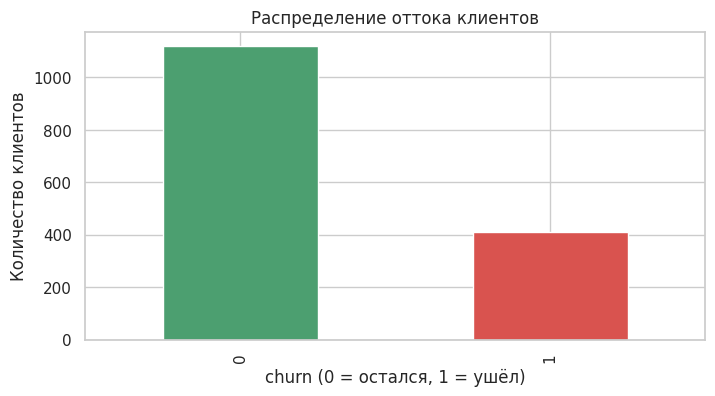

In [ ]:
df_raw["churn"].value_counts().plot(kind="bar", color=["#4C9F70", "#D9534F"])
plt.title("Распределение оттока клиентов")
plt.xlabel("churn (0 = остался, 1 = ушёл)"); plt.ylabel("Количество клиентов")
plt.show()

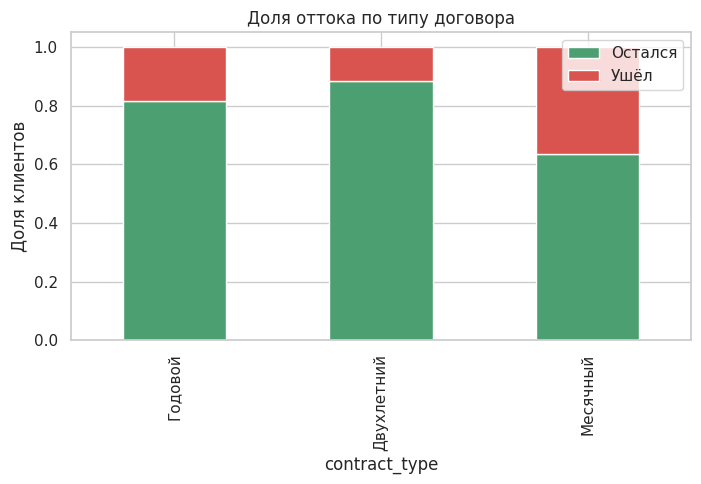

In [ ]:
# --- ПРИМЕР: связь типа договора (contract_type) с оттоком ---
pd.crosstab(df_raw["contract_type"], df_raw["churn"], normalize="index") \
    .plot(kind="bar", stacked=True, color=["#4C9F70", "#D9534F"])
plt.title("Доля оттока по типу договора")
plt.ylabel("Доля клиентов"); plt.legend(["Остался", "Ушёл"])
plt.show()


### ✍️ Задание 2

Постройте **минимум 3 разных графика** и сделайте выводы. Обязательно:

1. **Гистограмма** распределения `monthly_charges` (метод `.hist()` или `sns.histplot`). Виден ли выброс?
2. **Boxplot** признака `tenure_months` в разрезе `churn` (`sns.boxplot(x="churn", y="tenure_months", data=...)`). Отличается ли стаж у ушедших и оставшихся?
3. **Тепловая карта корреляций** числовых признаков (`sns.heatmap(df.corr(numeric_only=True), annot=True)`).
4. Дополнительно: **любой график на ваш выбор**, раскрывающий связь региона или способа оплаты с оттоком.

После графиков коротко опишите **2–3 замеченные закономерности** в текстовой ячейке.

> 🔒 Ваши распределения и корреляции индивидуальны — интерпретация будет своя.


In [ ]:
# ▼▼▼ ВАШ КОД (Задание 2) ▼▼▼

# График 1: гистограмма monthly_charges



In [ ]:
# График 2: boxplot tenure_months по churn



In [ ]:
# График 3: тепловая карта корреляций



In [ ]:
# График 4: на ваш выбор (регион / способ оплаты vs churn)


# ▲▲▲ КОНЕЦ ВАШЕГО КОДА ▲▲▲

**📝 Выводы по EDA** (впишите 2–3 закономерности из ВАШИХ данных):

1.

2.

3.


**❓ Контрольные вопросы к этапу 2:**

1. Что показывает boxplot и как по нему определить выбросы?
2. Корреляция и причинно-следственная связь — в чём разница? Приведите пример.
3. Зачем при дисбалансе классов (когда ушедших сильно меньше) простой точности (accuracy) может быть недостаточно?


*Ответы:*

1.

2.

3.


---
# 🧹 Этап 3. Предобработка данных

**Цель:** привести данные в порядок — убрать дубликаты, обработать пропуски и выбросы, привести текст к единому виду, закодировать категориальные признаки и при необходимости масштабировать числовые.

### 📖 Пример


In [ ]:
# --- ПРИМЕР: копия данных и удаление дубликатов ---
df = df_raw.copy()

before = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
print(f"Удалено дубликатов: {before - df.shape[0]}")

print("\nПропуски по столбцам:")
print(df.isna().sum())


Удалено дубликатов: 30

Пропуски по столбцам:
client_id            0
tenure_months        0
monthly_charges     45
total_charges       75
contract_type        0
internet_service     0
payment_method       0
support_calls        0
age                  0
region               0
churn                0
dtype: int64


In [ ]:
# --- ПРИМЕР: заполнение пропусков медианой (для одного столбца) ---
median_val = df["monthly_charges"].median()
df["monthly_charges"] = df["monthly_charges"].fillna(median_val)
print("Пропусков в monthly_charges после заполнения:", df["monthly_charges"].isna().sum())


Пропусков в monthly_charges после заполнения: 0


### ✍️ Задание 3

Работайте с переменной `df` (копией данных). Выполните:

1. **Пропуски.** Заполните пропуски в `total_charges`. Убедитесь, что пропусков не осталось.
2. **Текст.** Приведите столбец `region` к единому виду: уберите лишние пробелы (`.str.strip()`) и приведите к одному регистру (`.str.capitalize()`). Проверьте, что число уникальных регионов стало корректным.
4. **Кодирование.** Закодируйте категориальные признаки: `contract_type`, `internet_service`, `payment_method`, `region` через `pd.get_dummies()`.
5. Сохраните итоговый обработанный датафрейм в переменную `df_clean`.

> 🔒 Число пропусков и выбросов у вас своё — впишите фактические значения в отчёт.


In [ ]:
# ▼▼▼ ВАШ КОД (Задание 3) ▼▼▼
df = df_raw.copy().drop_duplicates().reset_index(drop=True)

# 1. Пропуски в total_charges



In [ ]:
# 2. Приведение region к единому виду



In [ ]:
# 3. Кодирование категориальных признаков (pd.get_dummies)


# 5. Итог
df_clean =   # <-- обработанный датафрейм

# ▲▲▲ КОНЕЦ ВАШЕГО КОДА ▲▲▲


**❓ Контрольные вопросы к этапу 3:**

1. Какими способами можно заполнять пропуски? Когда медиана предпочтительнее среднего?
2. Что такое One-Hot Encoding и почему нельзя просто заменить категории числами 1, 2, 3…?
3. В каких случаях числовые признаки нужно масштабировать, а в каких это не обязательно?


*Ответы:*

1.

2.

3.


---
# 🛠️ Этап 4. Конструирование и отбор признаков

**Цель:** создать новые информативные признаки (feature engineering) и отобрать наиболее полезные для будущей модели.

### 📖 Пример


In [ ]:
# --- ПРИМЕР: создание нового признака "средний платёж за месяц стажа" ---
df_clean_example = df_clean.copy() if "df_clean" in dir() else df.copy()

df_clean_example["avg_charge_per_tenure"] = (
    df_clean_example["total_charges"] / df_clean_example["tenure_months"].replace(0, 1))
df_clean_example[["total_charges", "tenure_months", "avg_charge_per_tenure"]].head()


### ✍️ Задание 4

Работайте с `df_clean`. Выполните:

1. **Создайте минимум 3 новых признака**, осмысленных с точки зрения экономики. Например:
   - `charges_per_call` — траты на одно обращение в поддержку;
   - `is_new_client` — флаг «новичок» (стаж < 6 месяцев);
   - `high_spender` — флаг «крупный клиент» (платёж выше медианы);
   - `tenure_group` — группировка стажа по корзинам (`pd.cut`).

2. **Отбор признаков.** Постройте корреляцию всех числовых признаков (включая новые) с целевой `churn` (`df.corr(numeric_only=True)["churn"].sort_values()`). Определите **топ-5 признаков**, наиболее связанных с оттоком.

3. Сформируйте финальную матрицу признаков `X` (без `churn` и `client_id`) и вектор целевой `y = df_clean["churn"]`. Выведите их размеры.

> 🔒 Топ признаков и их корреляции у каждого свои — это ваш индивидуальный результат.


In [ ]:
# ▼▼▼ ВАШ КОД (Задание 4) ▼▼▼

# 1. Новые признаки (минимум 3, один — свой)



In [ ]:
# 2. Отбор: корреляция признаков с churn, топ-5




In [ ]:
# 3. Финальные X и y
X =   # все признаки, кроме churn и client_id
y =   # df_clean["churn"]

# print("Размер X:", X.shape, "| Размер y:", y.shape)

# ▲▲▲ КОНЕЦ ВАШЕГО КОДА ▲▲▲

**❓ Контрольные вопросы к этапу 4:**

1. Что такое feature engineering и почему хорошие признаки часто важнее сложной модели?
2. Чем отбор признаков (feature selection) отличается от снижения размерности (например, PCA)?
3. Почему признак `client_id` нельзя подавать в модель как обычный признак?


*Ответы:*

1.

2.

3.


---
# 📋 Итоговый отчёт студента

Заполните таблицу и краткие выводы по результатам ВАШЕГО варианта. Это обязательная часть работы.


### Данные варианта

| Поле | Значение |
|------|----------|
| ФИО |  |
| Номер по списку |  |
| Персональный SEED |  |
| Число строк после удаления дубликатов |  |
| Доля оттока (churn=1), % |  |
| Найдено пропусков (всего) |  |
| Число признаков в финальной матрице X |  |




### ✅ Финальная самопроверка

Запустите ячейку ниже. Она проверит, что основные переменные заданы (это не оценка, а помощь себе).


In [ ]:
# --- Мягкая самопроверка (не влияет на оценку, помогает не забыть шаги) ---
problems = []

if "df_clean" not in dir() or df_clean is None:
    problems.append("Не создан df_clean (Этап 3).")
if "X" not in dir() or X is None:
    problems.append("Не создана матрица X (Этап 4).")
if "y" not in dir() or y is None:
    problems.append("Не создан вектор y (Этап 4).")

if not problems:
    print("✅ Отлично! Все ключевые переменные (df_clean, X, y) заданы.")
    print("Не забудьте заполнить таблицу и выводы в отчёте выше.")
else:
    print("⚠️ Обратите внимание:")
    for p in problems:
        print("  -", p)


---
### 📤 Как сдать работу

1. Убедитесь, что **все ячейки выполнены сверху вниз без ошибок** (`Среда выполнения → Перезапустить и выполнить всё`).
2. Проверьте, что заполнены **все текстовые ответы** и **итоговый отчёт**.
3. Сохраните блокнот: `Файл → Скачать → Скачать .ipynb`.
4. Переименуйте файл в формат `Фамилия_Имя_ПР1.ipynb` и загрузите в Moodle.

**Удачи! 🍀**
